In [ ]:
import random
import matplotlib.pyplot as plt
import numpy as np

import heapq

# Queueing Theory

In this project, I study a five-station bike-sharing network using analytical queueing models and discrete-event simulation. I begin with Kelly's closed migration process, then explore travel times, finite capacities, waiting queues, greedy rebalancing, and an alternative parallel-service assumption.

## Model 1: Closed migration process

In the first model, the assumptions are:

- Infinite Capacity: Stations never fill up. This eliminates entry
queues and rejection events.
- Instantaneous Travel (Teleportation): Transit times are exactly
zero (D = 0). Movement between stations is immediate.

I model five stations as a closed network of M/M/1 queues containing N bicycles, following the closed migration process described by Kelly and Yudovina:

- state space defined as:
$$S = \left\{ n \in \mathbb{Z}_+^J : \sum_{j=1}^J n_j = N \right\}$$

- The transition rate from a state $n$ to a new state $T_{jk}(n)$ , which changes from the previous one because one individual moves from $j$ to $k$, is given by the infinitesimal generator:
$$q(n, T_{jk}(n)) = \lambda_{jk} \phi_j(n_j)$$

In my case:
- The colonies are $J = 5$ stations with indices 3, 4, 5, 6, 7
- $\lambda_{jk} = \mu_j P_{jk}$, where $\mu_j$ is the base departure rate (demand) and $P_{jk}$ is the routing probability.
- indicator function is $\phi_j(n_j) = 1$ if $n_j > 0$ and $0$ otherwise.

To find the equilibrium, I solve the traffic equations:
$$\alpha_j \sum_{k} \lambda_{jk} = \sum_{k} \alpha_k \lambda_{kj}$$

Substituting my network's parameters:
$$\alpha_j \sum_{k} \mu_j P_{jk} = \sum_{k} \alpha_k \mu_k P_{kj}$$

Since $\sum_k P_{jk} = 1$ :
$$\alpha_j \mu_j = \sum_{k} \alpha_k \mu_k P_{kj}$$

I define a new vector $v_j = \alpha_j \mu_j$. The system becomes:
$$v_j = \sum_{k} v_k P_{kj} \quad \implies \quad \vec{v} = \vec{v}P$$
This implies that $\vec{v}$ is the invariant measure which exists and is unique for the following verification.

According to standard Markov chain theory, a continuous-time Markov process ($X$) admits a unique stationary probability if it is homogeneous, irreducible, and recurrent.

For this finite network, I check the following properties:
1. Homogeneous: The departure rates $\mu_j$ and routing probabilities $P_{jk}$ do not depend on the timestep.
2. Irreducible: The continuous process $X$ is irreducible if and only if its embedded discrete-time Markov chain ($\hat{X}$) is irreducible. All off-diagonal entries in my specific matrix $P$ are strictly positive so any station can be reached from any other station. Thus, $\hat{X}$ is irreducible, which implies $X$ is irreducible.
3. Recurrent: Because the state space is finite and the embedded chain is irreducible, all states in $\hat{X}$ are necessarily recurrent. Consequently, the continuous process $X$ is also recurrent.

Now that I have $\vec{v}$, I retrieve the original flow variables $\vec{\alpha}$. By definition:
$$\alpha_j = \frac{v_j}{\mu_j}$$

**Theorem 2.4:**
The stationary probability distribution for a closed migration process has a product form:
$$\pi(n) = G_N^{-1} \prod_{j=1}^J \frac{\alpha_j^{n_j}}{\prod_{r=1}^{n_j} \phi_j(r)}$$

The product form avoids solving the full system of state balance equations.

In classical Markov theory, finding the stationary distribution $\vec{\pi}$ requires solving:
$$\pi(\vec{n}) \sum_{\vec{n}' \neq \vec{n}} q(\vec{n}, \vec{n}') = \sum_{\vec{n}' \neq \vec{n}} \pi(\vec{n}') q(\vec{n}', \vec{n})$$

which means find the probability vector $\vec{\pi} = [\pi(\vec{n}_1), \pi(\vec{n}_2), \dots, \pi(\vec{n}_{|S|})]$ satisfying $\vec{\pi} Q = 0$ and $\sum \pi(\vec{n}) = 1$. The unknowns are the probabilities of every single configuration $\vec{n} = (n_3, n_4, n_5, n_6, n_7)$, using my rates $q(\vec{n}, T_{jk}(\vec{n})) = \mu_j P_{jk}$.

The size of the matrix $Q$ equals the total number of possible states $|S|$. But how many states are there?
Mathematically, I am looking for the number of non-negative integer solutions to the equation:
$$n_3 + n_4 + n_5 + n_6 + n_7 = N$$
In combinatorics, distributing $N$ identical items into $J$ distinct bins is a combination with repetition:
$$|S| = \binom{N + J - 1}{J - 1}$$

For **$N = 100$**  **$J = 5$**:
$$|S| = \binom{100 + 5 - 1}{5 - 1} = \binom{104}{4} = \mathbf{4,598,126 \text{ states}}$$

This means my $Q$ matrix would be $4,598,126 \times 4,598,126$ and direct balance would require solving a system with 4,598,126 equations.

It's also important to distinguish between the state probability $\pi(\vec{n})$ and the marginal bike distribution.

It is the probability of the system being in one specific configuration $\vec{n} = (n_3, n_4, n_5, n_6, n_7)$:
$$\pi(\vec{n}) = \frac{1}{G_N} \prod_{j=3}^7 \alpha_j^{n_j}$$

Marginal bike distribution represents the average fraction of the fleet located at station $i$:
$$\pi_i^{marginal} = p_L(i) = \int_S p_{L|\vec{n}}(i|\vec{n}) \pi(\vec{n}) \, d\nu(\vec{n}) = \int_S \frac{n_i}{N} \left( \frac{1}{G_N} \prod_{j=3}^7 \alpha_j^{n_j} \right) d\nu(\vec{n}) = \frac{1}{N \cdot G_N} \sum_{\vec{n} \in S} n_i \left( \prod_{j=3}^7 \alpha_j^{n_j} \right) = \frac{\mathbb{E}[n_i]}{N}$$

Case $N=1$:
$$\pi_i^{marginal} = \frac{\mathbb{E}[n_i]}{1} = \sum_{\vec{n} \in S} n_i \pi(\vec{n}) = \frac{1}{G_1} \sum_{\vec{n} \in S} n_i \left( \prod_{j=3}^7 \alpha_j^{n_j} \right) = \frac{\alpha_i}{G_1}$$

Case $N=100$:
$$\pi_i^{marginal} = \frac{\mathbb{E}[n_i]}{100} = \frac{1}{100} \sum_{\vec{n} \in S} n_i \pi(\vec{n}) = \frac{1}{100 \cdot G_{100}} \sum_{\vec{n} \in S} n_i \left( \prod_{j=3}^7 \alpha_j^{n_j} \right)$$


I apply this theory to fleets of one and 100 bicycles, then compare the analytical predictions with simulation.

In [ ]:
stations = [3, 4, 5, 6, 7]
mu = np.array([2.8, 3.7, 5.5, 3.5, 4.6])
P = np.array([
    [0.0,  0.2,  0.3,  0.2,  0.3 ],
    [0.2,  0.0,  0.3,  0.2,  0.3 ],
    [0.2,  0.25, 0.0,  0.25, 0.3 ],
    [0.15, 0.2,  0.3,  0.0,  0.35],
    [0.2,  0.25, 0.35, 0.2,  0.0 ]
])

**Analytical solution for N=1**

For a single bicycle $N=1$, the state space size is small:
$$|S| = \binom{1 + 5 - 1}{5 - 1} = \binom{5}{4} = 5 \text{ states}$$

The 5 basis vectors correspond simply to the location of the bike:
$\vec{n}_3 = (1, 0, 0, 0, 0)$, $\vec{n}_4 = (0, 1, 0, 0, 0)$, ...

Because the state space is so small, I can solve this problem in 3 different ways to check agreement with Kelly's theorem in this example:
1. Closed migration process shortcut (Kelly's Product Form)
2. Classical Markov Approach (Solving $\vec{\pi} Q = 0$ directly)
3. Sample-path simulation

I begin with the product-form expression.

1.

According to Theorem 2.4, the product form is:
$$\pi(\vec{n}) = G_1^{-1} \prod_{j=3}^7 \frac{\alpha_j^{n_j}}{\prod_{r=1}^{n_j} \phi_j(r)}$$

WLOG, consider $\vec{n}_3 = (1, 0, 0, 0, 0)$:
$$\pi(\vec{n}_3) = G_1^{-1} \left[ \left( \frac{\alpha_3^1}{\phi_3(1)} \right) \cdot \left( \frac{\alpha_4^0}{\prod_{r=1}^0 \phi_4(r)} \right) \cdot \left( \frac{\alpha_5^0}{\prod_{r=1}^0 \phi_5(r)} \right) \cdot \left( \frac{\alpha_6^0}{\prod_{r=1}^0 \phi_6(r)} \right) \cdot \left( \frac{\alpha_7^0}{\prod_{r=1}^0 \phi_7(r)} \right) \right]$$

By mathematical convention, an empty product evaluates to $1$, and the indicator function is $1$:
$$\pi(\vec{n}_3) = G_1^{-1} \cdot \left( \frac{\alpha_3}{1} \right) \cdot 1 \cdot 1 \cdot 1 \cdot 1 = G_1^{-1} \alpha_3$$

This is generally true for any state:
$$\pi(\vec{n}_i) = G_1^{-1} \alpha_i$$

From the traffic equations, the relative flows are $\alpha_i = \frac{v_i}{\mu_i}$, where $\vec{v}$ is the invariant measure of the routing matrix $P$ and $\vec{\mu}$ are the departure rates. Thus:
$$\pi(\vec{n}_i) = G_1^{-1} \frac{v_i}{\mu_i}$$

To find the normalization constant $G_1$, I use the probability axiom $\sum_{i=3}^7 \pi(\vec{n}_i) = 1$:
$$1 = G_1^{-1} \sum_{i=3}^7 \frac{v_i}{\mu_i} \quad \implies \quad G_1 = \sum_{i=3}^7 \frac{v_i}{\mu_i}$$

**Deriving the Analytical Values:**
I first calculate $\vec{v} = [v_3, v_4, v_5, v_6, v_7]$. By definition, it is the solution to $\vec{v} = \vec{v}P$ subject to $\sum v_i = 1$.
Given my explicit routing matrix $P$:
$$P = \begin{pmatrix}
0.0 & 0.2 & 0.3 & 0.2 & 0.3 \\
0.2 & 0.0 & 0.3 & 0.2 & 0.3 \\
0.2 & 0.25 & 0.0 & 0.25 & 0.3 \\
0.15 & 0.2 & 0.3 & 0.0 & 0.35 \\
0.2 & 0.25 & 0.35 & 0.2 & 0.0
\end{pmatrix}$$

The matrix equation $\vec{v} = \vec{v}P$ translates directly into this system of linear equations (reading the columns of $P$):
$$
\begin{cases}
v_3 = 0.0 v_3 + 0.2 v_4 + 0.2 v_5 + 0.15 v_6 + 0.2 v_7 \\
v_4 = 0.2 v_3 + 0.0 v_4 + 0.25 v_5 + 0.2 v_6 + 0.25 v_7 \\
v_5 = 0.3 v_3 + 0.3 v_4 + 0.0 v_5 + 0.3 v_6 + 0.35 v_7 \\
v_6 = 0.2 v_3 + 0.2 v_4 + 0.25 v_5 + 0.0 v_6 + 0.2 v_7 \\
v_7 = 0.3 v_3 + 0.3 v_4 + 0.3 v_5 + 0.35 v_6 + 0.0 v_7 \\
v_3 + v_4 + v_5 + v_6 + v_7 = 1
\end{cases}
$$

Solving this deterministic system yields the numerical invariant probability vector:
$$\vec{v} \approx [0.159, \ 0.187, \ 0.240, \ 0.177, \ 0.238]^T$$

Now, combining this derived vector with my known departure rates $\vec{\mu} = [2.8, \ 3.7, \ 5.5, \ 3.5, \ 4.6]^T$, I compute the explicit $\alpha_i$ values ($\alpha_i = \frac{v_i}{\mu_i}$):
* $\alpha_3 = \frac{0.159}{2.8} \approx 0.057$
* $\alpha_4 = \frac{0.187}{3.7} \approx 0.050$
* $\alpha_5 = \frac{0.240}{5.5} \approx 0.044$
* $\alpha_6 = \frac{0.177}{3.5} \approx 0.051$
* $\alpha_7 = \frac{0.238}{4.6} \approx 0.052$

Next, I sum these to find the explicit normalization constant $G_1$:
$$G_1 = 0.057 + 0.050 + 0.044 + 0.051 + 0.052 = 0.254$$

Finally, dividing each $\alpha_i$ by $G_1$ provides the probability for each state which corresponds for the case N=1 to the marginal probability:
* $\pi(1, 0, 0, 0, 0) = \pi_3^{marginal} = \frac{0.057}{0.254} \approx 22.44\%$
* $\pi(0, 1, 0, 0, 0) = \pi_4^{marginal} = \frac{0.050}{0.254} \approx 19.68\%$
* $\pi(0, 0, 1, 0, 0) = \pi_5^{marginal} = \frac{0.044}{0.254} \approx 17.32\%$
* $\pi(0, 0, 0, 1, 0) = \pi_6^{marginal} = \frac{0.051}{0.254} \approx 20.07\%$
* $\pi(0, 0, 0, 0, 1) = \pi_7^{marginal} = \frac{0.052}{0.254} \approx 20.47\%$


In [ ]:
A = np.array([
    [-1.0,  0.2,  0.2,  0.15, 0.2 ],  # eq for v_3: -v_3 + 0.2*v_4 + ... = 0
    [ 0.2, -1.0,  0.25, 0.2,  0.25],  # eq for v_4
    [ 0.3,  0.3, -1.0,  0.3,  0.35],  # eq v_5
    [ 0.2,  0.2,  0.25,-1.0,  0.2 ],  # eq v_6
    [ 1.0,  1.0,  1.0,  1.0,  1.0 ]   # eq: v_3 + v_4 + v_5 + v_6 + v_7 = 1
])

b = np.array([0.0, 0.0, 0.0, 0.0, 1.0])

#solve system
v = np.linalg.solve(A, b)

alpha = v / mu

G_1 = np.sum(alpha)
pi_theoretical = alpha / G_1

pi_3 = pi_theoretical[0]
pi_4 = pi_theoretical[1]
pi_5 = pi_theoretical[2]
pi_6 = pi_theoretical[3]
pi_7 = pi_theoretical[4]

print("--- KELLY'S PRODUCT FORM SOLUTION (N=1) ---")
for i, stat in enumerate(stations):
    print(f"Station {stat}: {pi_theoretical[i]:.4f} ({pi_theoretical[i]*100:.2f}%)")

--- KELLY'S PRODUCT FORM SOLUTION (N=1) ---
Station 3: 0.2248 (22.48%)
Station 4: 0.1993 (19.93%)
Station 5: 0.1724 (17.24%)
Station 6: 0.1995 (19.95%)
Station 7: 0.2041 (20.41%)


2.


I have:
$$q_{ij} = \mu_i P_{ij} \quad \text{for } i \neq j$$

To satisfy probability conservation, the diagonal elements must be the negative sum of the rest of the row. Since the probability of staying in the same station is zero ($P_{ii} = 0$), the sum of the outgoing rates is exactly the departure rate $\mu_i$:
$$q_{ii} = - \mu_i$$

Symbolically, the matrix looks like this:
$$Q = \begin{pmatrix}
-\mu_3 & \mu_3 P_{3,4} & \mu_3 P_{3,5} & \mu_3 P_{3,6} & \mu_3 P_{3,7} \\
\mu_4 P_{4,3} & -\mu_4 & \mu_4 P_{4,5} & \mu_4 P_{4,6} & \mu_4 P_{4,7} \\
\mu_5 P_{5,3} & \mu_5 P_{5,4} & -\mu_5 & \mu_5 P_{5,6} & \mu_5 P_{5,7} \\
\mu_6 P_{6,3} & \mu_6 P_{6,4} & \mu_6 P_{6,5} & -\mu_6 & \mu_6 P_{6,7} \\
\mu_7 P_{7,3} & \mu_7 P_{7,4} & \mu_7 P_{7,5} & \mu_7 P_{7,6} & -\mu_7
\end{pmatrix}$$


$$Q = \begin{pmatrix}
-2.80 & 0.56 & 0.84 & 0.56 & 0.84 \\
 0.74 & -3.70 & 1.11 & 0.74 & 1.11 \\
 1.10 & 1.375 & -5.50 & 1.375 & 1.65 \\
 0.525 & 0.70 & 1.05 & -3.50 & 1.225 \\
 0.92 & 1.15 & 1.61 & 0.92 & -4.60
\end{pmatrix}$$

I solve:
$$\vec{\pi} Q = 0$$
subject to $\sum_{i=3}^7 \pi_i = 1$

In [ ]:
#build Q
Q = np.zeros((5, 5))
for i in range(5):
    for j in range(5):
        if i != j:
            Q[i, j] = mu[i] * P[i, j]
    Q[i, i] = -mu[i]
A = Q.T.copy()

# Replace the last row with the normalization constraint: sum(pi) = 1
A[-1] = [1.0, 1.0, 1.0, 1.0, 1.0]
b = [0.0, 0.0, 0.0, 0.0, 1.0]#the last 1 is for the normaliz. constraint

pi_classical = np.linalg.solve(A, b)

print("--- CLASSICAL Q-MATRIX SOLUTION (N=1) ---")
for i, stat in enumerate(stations):
    print(f"Station {stat}: {pi_classical[i]:.4f} ({pi_classical[i]*100:.2f}%)")

--- CLASSICAL Q-MATRIX SOLUTION (N=1) ---
Station 3: 0.2248 (22.48%)
Station 4: 0.1993 (19.93%)
Station 5: 0.1724 (17.24%)
Station 6: 0.1995 (19.95%)
Station 7: 0.2041 (20.41%)


**Analytical solution for N=100**

1.

I start from
$\vec{n}_{0} = (20, 20, 20, 20, 20)$


$$\pi(\vec{n}) = G_{100}^{-1} \prod_{j=3}^7 \frac{\alpha_j^{n_j}}{\prod_{r=1}^{n_j} \phi_j(r)}= G_{100}^{-1} \left[ \left( \frac{\alpha_3^{20}}{\prod_{r=1}^{20} \phi_3(r)} \right) \cdot \left( \frac{\alpha_4^{20}}{\prod_{r=1}^{20} \phi_4(r)} \right) \cdot \left( \frac{\alpha_5^{20}}{\prod_{r=1}^{20} \phi_5(r)} \right) \cdot \left( \frac{\alpha_6^{20}}{\prod_{r=1}^{20} \phi_6(r)} \right) \cdot \left( \frac{\alpha_7^{20}}{\prod_{r=1}^{20} \phi_7(r)} \right) \right]$$

all denominators evaluate exactly to $1$:
$$\pi(20, 20, 20, 20, 20) = G_{100}^{-1} \left( \alpha_3^{20} \cdot \alpha_4^{20} \cdot \alpha_5^{20} \cdot \alpha_6^{20} \cdot \alpha_7^{20} \right)$$

It's true for all $\vec{n} = (n_3, n_4, n_5, n_6, n_7)$:
$$\pi(\vec{n}) = G_{100}^{-1} \left( \alpha_3^{n_3} \cdot \alpha_4^{n_4} \cdot \alpha_5^{n_5} \cdot \alpha_6^{n_6} \cdot \alpha_7^{n_7} \right)$$

I calculate $\vec{v} = [v_3, v_4, v_5, v_6, v_7]$ exactly as I did for $N=1$, solving $\vec{v} = \vec{v}P$ subject to $\sum v_i = 1$:
$$P = \begin{pmatrix}
0.0 & 0.2 & 0.3 & 0.2 & 0.3 \\
0.2 & 0.0 & 0.3 & 0.2 & 0.3 \\
0.2 & 0.25 & 0.0 & 0.25 & 0.3 \\
0.15 & 0.2 & 0.3 & 0.0 & 0.35 \\
0.2 & 0.25 & 0.35 & 0.2 & 0.0
\end{pmatrix}$$

getting the exact same invariant measure vector:
$$\vec{v} \approx [0.159, \ 0.187, \ 0.240, \ 0.177, \ 0.238]^T$$

I compute the identical explicit $\alpha_i$ values ($\alpha_i = \frac{v_i}{\mu_i}$):
* $\alpha_3 = \frac{0.159}{2.8} \approx 0.057$
* $\alpha_4 = \frac{0.187}{3.7} \approx 0.050$
* $\alpha_5 = \frac{0.240}{5.5} \approx 0.044$
* $\alpha_6 = \frac{0.177}{3.5} \approx 0.051$
* $\alpha_7 = \frac{0.238}{4.6} \approx 0.052$

The normalization constant $G_{100}$,changes:
$$1 = G_{100}^{-1} \sum_{\vec{n} \in S} \left( \alpha_3^{n_3} \cdot \alpha_4^{n_4} \cdot \alpha_5^{n_5} \cdot \alpha_6^{n_6} \cdot \alpha_7^{n_7} \right)$$
$$\implies G_{100} = \sum_{\vec{n} \in S} \left( \alpha_3^{n_3} \cdot \alpha_4^{n_4} \cdot \alpha_5^{n_5} \cdot \alpha_6^{n_6} \cdot \alpha_7^{n_7} \right)$$

In [ ]:
A = np.array([
    [-1.0,  0.2,  0.2,  0.15, 0.2 ],
    [ 0.2, -1.0,  0.25, 0.2,  0.25],
    [ 0.3,  0.3, -1.0,  0.3,  0.35],
    [ 0.2,  0.2,  0.25,-1.0,  0.2 ],
    [ 1.0,  1.0,  1.0,  1.0,  1.0 ]
])
b = np.array([0.0, 0.0, 0.0, 0.0, 1.0])

v = np.linalg.solve(A, b)
alpha = v / mu

N = 100
G_100 = 0.0

expected_n_unnorm = np.zeros(5)

for n3 in range(N + 1):
    for n4 in range(N + 1 - n3):
        for n5 in range(N + 1 - n3 - n4):
            for n6 in range(N + 1 - n3 - n4 - n5):
                n7 = N - n3 - n4 - n5 - n6

                unnorm_prob = (alpha[0]**n3) * (alpha[1]**n4) * (alpha[2]**n5) * (alpha[3]**n6) * (alpha[4]**n7)

                G_100 += unnorm_prob

                expected_n_unnorm[0] += n3 * unnorm_prob
                expected_n_unnorm[1] += n4 * unnorm_prob
                expected_n_unnorm[2] += n5 * unnorm_prob
                expected_n_unnorm[3] += n6 * unnorm_prob
                expected_n_unnorm[4] += n7 * unnorm_prob


# exp val
expected_bikes = expected_n_unnorm / G_100

# marginal
marginal_pi = expected_bikes / N

print("--- THEORETICAL MARGINAL DISTRIBUTION (N=100) ---")
for i, stat in enumerate(stations):
    print(f"Station {stat}: Avg Bikes = {expected_bikes[i]:.2f} | pi = {marginal_pi[i]:.4f} ({marginal_pi[i]*100:.2f}%)")

--- THEORETICAL MARGINAL DISTRIBUTION (N=100) ---
Station 3: Avg Bikes = 71.35 | pi = 0.7135 (71.35%)
Station 4: Avg Bikes = 7.76 | pi = 0.0776 (7.76%)
Station 5: Avg Bikes = 3.28 | pi = 0.0328 (3.28%)
Station 6: Avg Bikes = 7.83 | pi = 0.0783 (7.83%)
Station 7: Avg Bikes = 9.77 | pi = 0.0977 (9.77%)


### Direct balance equations for 100 bicycles

For $N=100$ and $J=5$, the state space contains $4,598,126$ configurations. Constructing and solving the full balance system would be expensive. I therefore use the product-form solution rather than a full generator matrix.

**Simulation for N=1**

Number events generated: 3955356
------------------------------------------------
Number of events per single station:
Station 3: 630513 events
Station 4: 737390 events
Station 5: 948926 events
Station 6: 698091 events
Station 7: 940436 events
------------------------------------------------
Experimental Invariant Probability Distribution:
Station 3: 0.2248 (22.48%)
Station 4: 0.1990 (19.90%)
Station 5: 0.1726 (17.26%)
Station 6: 0.1991 (19.91%)
Station 7: 0.2045 (20.45%)


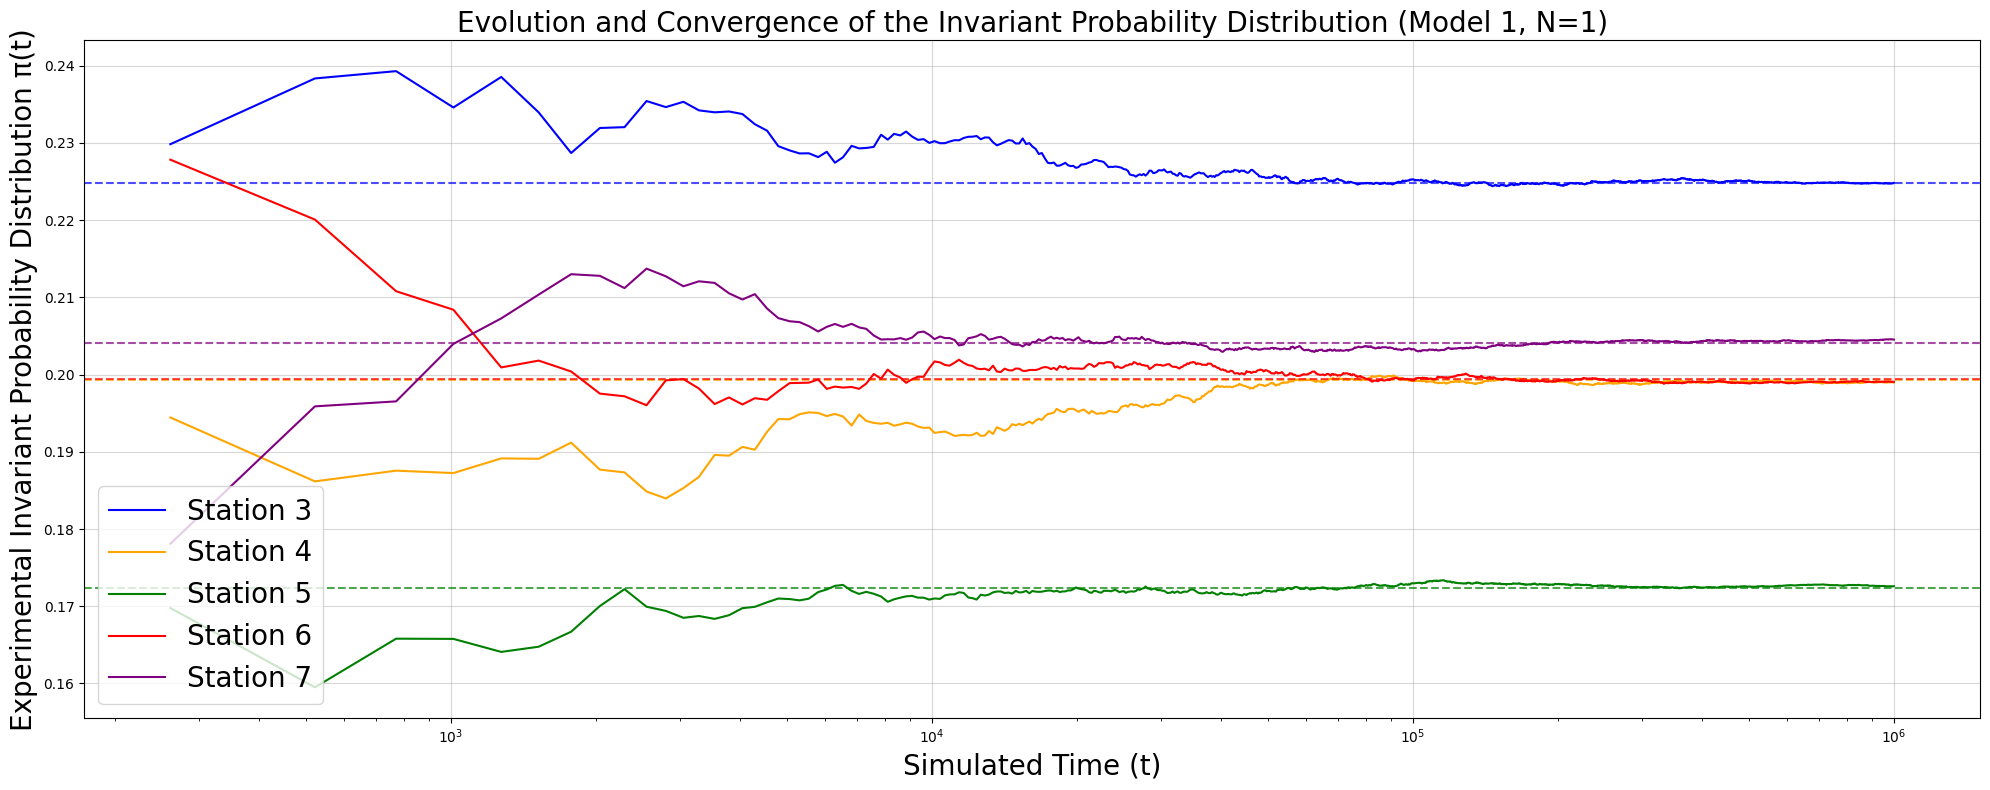

In [ ]:
random.seed(42)  # For reproducibility

def simulation1(mu, P, t_max, initial_station, record_step=1000):
    station = initial_station
    t = 0
    n = 0
    time_stations = np.zeros(5)
    n_stations = np.zeros(5)

    history_pi = []
    history_t = []

    while t < t_max:
        x = random.expovariate(mu[station])

        if t + x > t_max:
            time_stations[station] += (t_max - t)
            history_pi.append(time_stations / t_max)
            history_t.append(t_max)
            break

        time_stations[station] += x
        n_stations[station] += 1
        t += x
        n += 1

        if n % record_step == 0:
            current_pi = time_stations / t
            history_pi.append(current_pi)
            history_t.append(t)

        station = random.choices([0, 1, 2, 3, 4], weights=P[station])[0]

    return n, n_stations, time_stations, history_pi, history_t


t_max = 1000000
initial_station = 0

# Rimosso event_times dall'unpacking
n, n_stations, time_stations, history_pi, history_t = simulation1(mu, P, t_max, initial_station)

print(f"Number events generated: {n}")
print("-" * 48)

print("Number of events per single station:")
for i in range(5):
    print(f"Station {stations[i]}: {int(n_stations[i])} events")
print("-" * 48)

print("Experimental Invariant Probability Distribution:")
for i in range(5):
    pi_final = time_stations[i] / t_max
    print(f"Station {stations[i]}: {pi_final:.4f} ({pi_final*100:.2f}%)")

history_pi_array = np.array(history_pi)

# PLOTTING THE EVOLUTION OF THE INVARIANT PROBABILITY DISTRIBUTION
plt.figure(figsize=(20, 8))

colors = ['blue', 'orange', 'green', 'red', 'purple']

for i in range(5):
    plt.plot(history_t, history_pi_array[:, i], label=f'Station {stations[i]}', color=colors[i], linewidth=1.5)
    plt.axhline(y=pi_theoretical[i], color=colors[i], linestyle='--', alpha=0.7)

plt.xlabel('Simulated Time (t)', fontsize=20)
plt.ylabel('Experimental Invariant Probability Distribution \u03C0(t)', fontsize=20)
plt.title('Evolution and Convergence of the Invariant Probability Distribution (Model 1, N=1)', fontsize=20)
plt.legend(fontsize=20)
plt.grid(True, alpha=0.5)

plt.xscale('log')
plt.tight_layout()

plt.show()


I observe that empirical marginal probabilities converge to theoretical marginal probabilities previously computed.

My system, modeled as a continuous-time Markov chain denoted by $X = (X(t), t \ge 0)$, is homogeneous, irreducible, and positive recurrent. According to the Ergodic Theorem, for any bounded function $f: S \to \mathbb{R}$:

$$\lim_{T \to \infty} \frac{1}{T} \int_0^T f(X(t)) \, dt = \sum_{\vec{n} \in S} f(\vec{n}) \pi(\vec{n}) = \mathbb{E}_{\pi}[f]$$

Here, $X(t) \in S$ indicates the state vector of the system at time $t$. By setting $f(X(t)) = n_i(t)$, which represents the number of bicycles at station $i$ at time $t$, I obtain the marginal probability:

$$\lim_{T \to \infty} \frac{1}{T} \int_0^T n_i(t) \, dt = \sum_{\vec{n} \in S} n_i \pi(\vec{n}) = \frac{\mathbb{E}[n_i]}{1} = \pi_i^{marginal}$$

Since I cannot simulate for $T \to \infty$, I use a finite horizon $T = t_{max}$ to approximate long-run behavior. This yields my estimator, denoted with a hat ($\hat{\pi}$):

$$\hat{\pi}_i^{marginal} = \frac{\text{time\_stations}[i]}{t_{max}} = \frac{1}{t_{max}} \int_0^{t_{max}} n_i(t) \, dt$$

$$\text{Bias}(\hat{\pi}_i^{marginal}) = \mathbb{E}\left[ \hat{\pi}_i^{marginal} \right] - \pi_i^{marginal} = \mathbb{E}\left[ \frac{1}{t_{max}} \int_0^{t_{max}} n_i(t) \, dt \right] - \pi_i^{marginal} = \frac{1}{t_{max}} \int_0^{t_{max}} \mathbb{E}[n_i(t)] \, dt - \pi_i^{marginal} \xrightarrow[t_{max} \to \infty]{} 0$$



$$\text{Var}(\hat{\pi}_i^{marginal}) = \text{Var}\left( \frac{1}{t_{max}} \int_0^{t_{max}} n_i(t) \, dt \right) = \frac{1}{t_{max}^2} \int_0^{t_{max}} \int_0^{t_{max}} \text{Cov}\left(n_i(t), n_i(s)\right) \, dt \, ds = \frac{2}{t_{max}^2} \int_0^{t_{max}} (t_{max}-\tau) \text{Cov}\left(n_i(\tau), n_i(0)\right) \, d\tau \approx \frac{2}{t_{max}} \int_0^\infty \text{Cov}\left(n_i(\tau), n_i(0)\right) \, d\tau = \mathcal{O}\left(\frac{1}{t_{max}}\right) \xrightarrow[t_{max} \to \infty]{} 0$$

For any homogeneous, irreducible, and positive recurrent continuous-time MC, the steady-state joint distribution is strictly independent of the initial state $X(0) = \vec{n}_0$:

$$\lim_{t \to \infty} \mathbb{P}(X(t) = \vec{n} \mid X(0) = \vec{n}_0) = \pi(\vec{n})$$

this property naturally extends to the marginal probabilities:

$$
\begin{aligned}
\lim_{t \to \infty} \mathbb{E}[n_i(t) \mid X(0) = \vec{n}_0] &= \lim_{t \to \infty} \sum_{\vec{n} \in S} n_i \cdot \mathbb{P}(X(t) = \vec{n} \mid X(0) = \vec{n}_0) \\
&= \sum_{\vec{n} \in S} n_i \left( \lim_{t \to \infty} \mathbb{P}(X(t) = \vec{n} \mid X(0) = \vec{n}_0) \right) \\
&= \sum_{\vec{n} \in S} n_i \pi(\vec{n}) \\
&= \pi_i^{marginal}
\end{aligned}
$$


In my model, this guarantees that the arbitrary initial placement of the bicycle (`initial_station = 0`, i.e., Station 3) introduces only a temporary transient bias. As $t_{max} \to \infty$, the network completely "forgets" this starting configuration, ensuring that my empirical simulation converges asymptotically to Kelly's theoretical distribution.

**Simulation for N=100**

Number events generated: 17566462
------------------------------------------------
Number of events per single station:
Station 3: 2798198 events
Station 4: 3278349 events
Station 5: 4214542 events
Station 6: 3104448 events
Station 7: 4170925 events
------------------------------------------------
Experimental Invariant Probability Distribution:
Station 3: 0.7146 (71.46%) -> Avg bikes: 71.46
Station 4: 0.0775 (7.75%) -> Avg bikes: 7.75
Station 5: 0.0327 (3.27%) -> Avg bikes: 3.27
Station 6: 0.0783 (7.83%) -> Avg bikes: 7.83
Station 7: 0.0969 (9.69%) -> Avg bikes: 9.69


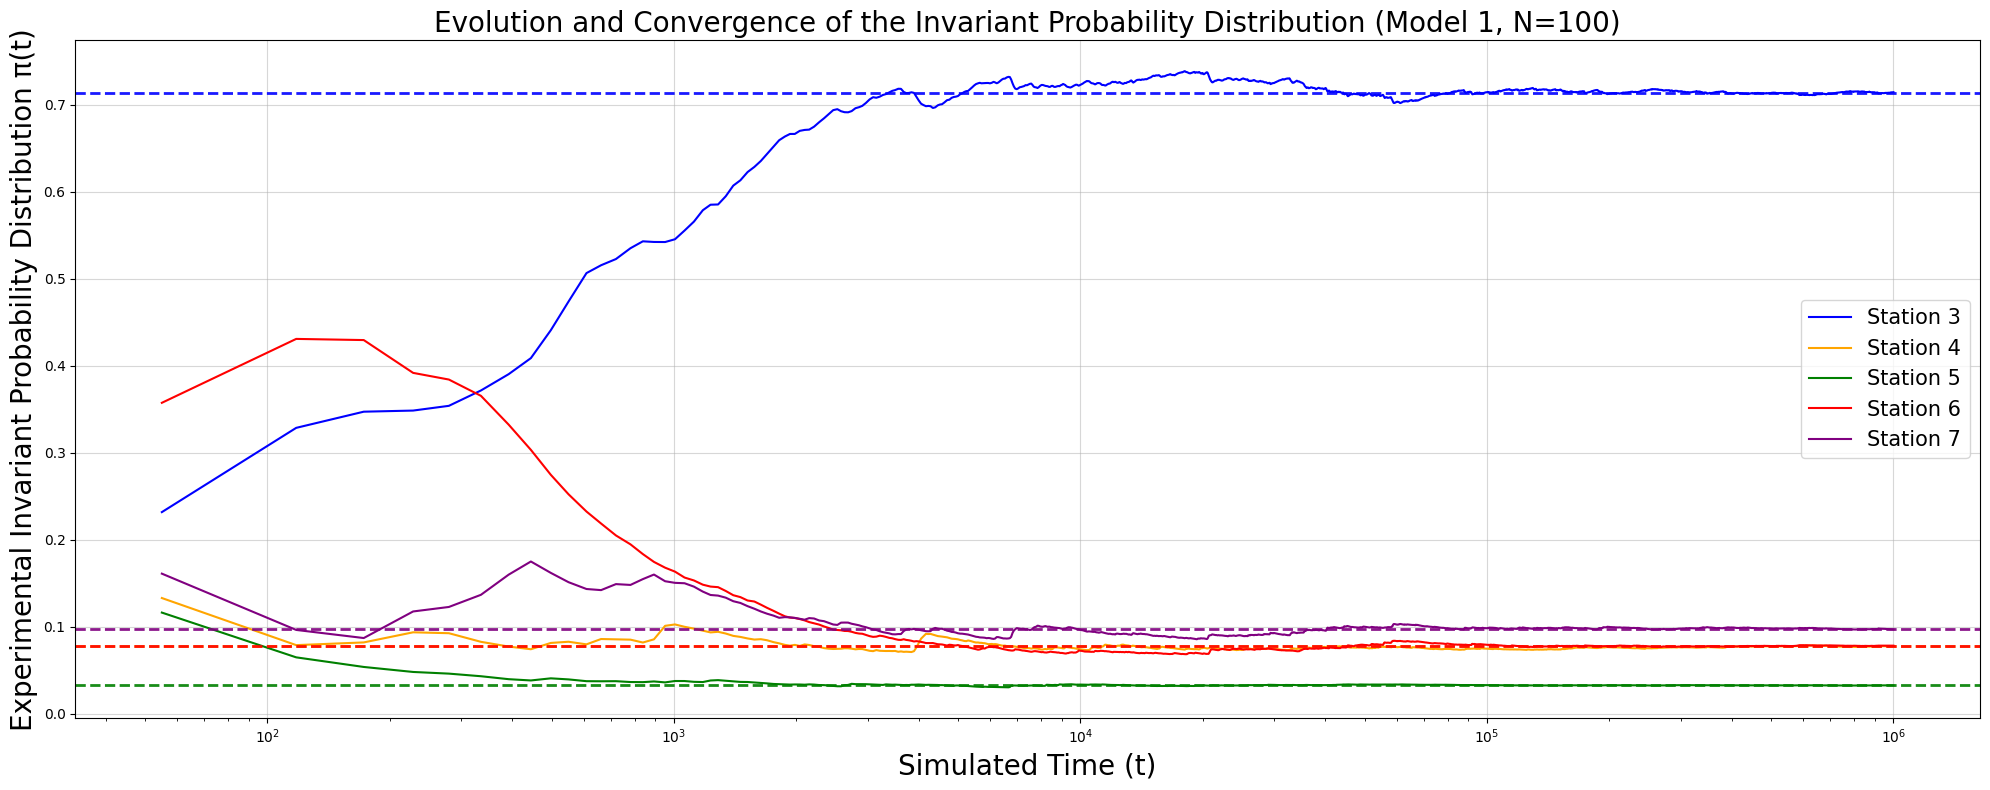

In [ ]:
random.seed(42)  # For reproducibility


def simulation100(mu, P, t_max, initial_bikes, record_step=1000):
    state = initial_bikes.copy()
    N_total = sum(state)

    t = 0
    n = 0
    bike_time_integral = np.zeros(5)
    n_stations = np.zeros(5)

    history_pi = []
    history_t = []

    while t < t_max:
        #superposition

        active_rates = [mu[i] if state[i] > 0 else 0 for i in range(5)]
        total_rate = sum(active_rates)

        x = random.expovariate(total_rate)

        if t + x > t_max:
            for i in range(5):
                bike_time_integral[i] += state[i] * (t_max - t)

            history_pi.append((bike_time_integral / t_max) / N_total)
            history_t.append(t_max)
            break

        for i in range(5):
            bike_time_integral[i] += state[i] * x

        origin = random.choices([0, 1, 2, 3, 4], weights=active_rates)[0]

        n_stations[origin] += 1
        t += x
        n += 1

        if n % record_step == 0:
            current_pi = (bike_time_integral / t) / N_total
            history_pi.append(current_pi)
            history_t.append(t)

        destination = random.choices([0, 1, 2, 3, 4], weights=P[origin])[0]

        state[origin] -= 1
        state[destination] += 1

    return n, n_stations, bike_time_integral, history_pi, history_t


t_max = 1000000
initial_bikes = [20, 20, 20, 20, 20]

n, n_stations, bike_time_integral, history_pi, history_t = simulation100(mu, P, t_max, initial_bikes)

print(f"Number events generated: {n}")
print("-" * 48)

print("Number of events per single station:")
for i in range(5):
    print(f"Station {stations[i]}: {int(n_stations[i])} events")
print("-" * 48)

print("Experimental Invariant Probability Distribution:")
N_total = sum(initial_bikes)
for i in range(5):
    avg_bikes = bike_time_integral[i] / t_max
    pi_final = avg_bikes / N_total
    print(f"Station {stations[i]}: {pi_final:.4f} ({pi_final*100:.2f}%) -> Avg bikes: {avg_bikes:.2f}")

history_pi_array = np.array(history_pi)

# PLOTTING THE EVOLUTION OF THE INVARIANT PROBABILITY DISTRIBUTION
plt.figure(figsize=(20, 8))
colors = ['blue', 'orange', 'green', 'red', 'purple']

for i in range(5):
    plt.plot(history_t, history_pi_array[:, i], label=f'Station {stations[i]}', color=colors[i], linewidth=1.5)
    plt.axhline(y=marginal_pi[i], color=colors[i], linestyle='--', alpha=0.9, linewidth=2)

plt.xlabel('Simulated Time (t)', fontsize=20)
plt.ylabel('Experimental Invariant Probability Distribution \u03C0(t)', fontsize=20)
plt.title('Evolution and Convergence of the Invariant Probability Distribution (Model 1, N=100)', fontsize=20)
plt.legend(fontsize=15)
plt.grid(True, alpha=0.5)

plt.xscale('log')
plt.tight_layout()
plt.show()

I observe that empirical marginal probabilities converge to theoretical marginal probabilities previously computed.

My system, modeled as a continuous-time Markov chain denoted by $X = (X(t), t \ge 0)$, is homogeneous, irreducible, and positive recurrent. According to the Ergodic Theorem, for any bounded function $f: S \to \mathbb{R}$:

$$\lim_{T \to \infty} \frac{1}{T} \int_0^T f(X(t)) \, dt = \sum_{\vec{n} \in S} f(\vec{n}) \pi(\vec{n}) = \mathbb{E}_{\pi}[f]$$

Here, $X(t) \in S$ indicates the global state vector of the system at time $t$. By setting $f(X(t)) = n_i(t)$, which represents the number of bicycles at station $i$ at time $t$, and normalizing by the total fleet size $N=100$, I obtain the marginal probability:

$$\lim_{T \to \infty} \frac{1}{100 \cdot T} \int_0^T n_i(t) \, dt = \frac{1}{100} \sum_{\vec{n} \in S} n_i \pi(\vec{n}) = \frac{\mathbb{E}[n_i]}{100} = \pi_i^{marginal}$$

Since I cannot simulate for $T \to \infty$, I use a finite horizon $T = t_{max}$ to approximate long-run behavior. This yields my estimator, denoted with a hat ($\hat{\pi}$):

$$\hat{\pi}_i^{marginal} = \frac{\text{sum\_bikes\_time}[i]}{100 \cdot t_{max}} = \frac{1}{100 \cdot t_{max}} \int_0^{t_{max}} n_i(t) \, dt$$

$$\text{Bias}(\hat{\pi}_i^{marginal}) = \mathbb{E}\left[ \hat{\pi}_i^{marginal} \right] - \pi_i^{marginal} = \mathbb{E}\left[ \frac{1}{100 \cdot t_{max}} \int_0^{t_{max}} n_i(t) \, dt \right] - \pi_i^{marginal} = \frac{1}{100 \cdot t_{max}} \int_0^{t_{max}} \mathbb{E}[n_i(t)] \, dt - \pi_i^{marginal} \xrightarrow[t_{max} \to \infty]{} 0$$

$$\text{Var}(\hat{\pi}_i^{marginal}) = \text{Var}\left( \frac{1}{100 \cdot t_{max}} \int_0^{t_{max}} n_i(t) \, dt \right) = \frac{1}{100^2 \cdot t_{max}^2} \int_0^{t_{max}} \int_0^{t_{max}} \text{Cov}\left(n_i(t), n_i(s)\right) \, dt \, ds = \frac{2}{100^2 \cdot t_{max}^2} \int_0^{t_{max}} (t_{max}-\tau) \text{Cov}\left(n_i(\tau), n_i(0)\right) \, d\tau \approx \frac{2}{100^2 \cdot t_{max}} \int_0^\infty \text{Cov}\left(n_i(\tau), n_i(0)\right) \, d\tau = \mathcal{O}\left(\frac{1}{t_{max}}\right) \xrightarrow[t_{max} \to \infty]{} 0$$

For any homogeneous, irreducible, and positive recurrent continuous-time MC, the steady-state joint distribution is strictly independent of the initial state $X(0) = \vec{n}_0$:

$$\lim_{t \to \infty} \mathbb{P}(X(t) = \vec{n} \mid X(0) = \vec{n}_0) = \pi(\vec{n})$$

This property naturally extends to the marginal probabilities:

$$
\begin{aligned}
\lim_{t \to \infty} \frac{1}{100} \mathbb{E}[n_i(t) \mid X(0) = \vec{n}_0] &= \lim_{t \to \infty} \frac{1}{100} \sum_{\vec{n} \in S} n_i \cdot \mathbb{P}(X(t) = \vec{n} \mid X(0) = \vec{n}_0) \\
&= \frac{1}{100} \sum_{\vec{n} \in S} n_i \left( \lim_{t \to \infty} \mathbb{P}(X(t) = \vec{n} \mid X(0) = \vec{n}_0) \right) \\
&= \frac{1}{100} \sum_{\vec{n} \in S} n_i \pi(\vec{n}) \\
&= \pi_i^{marginal}
\end{aligned}
$$

In my model, this guarantees that the arbitrary initial placement of the 100 bicycles (`initial_bikes = [20, 20, 20, 20, 20]`) introduces only a temporary transient bias. As $t_{max} \to \infty$, the network completely "forgets" this starting configuration, ensuring that my empirical simulation converges asymptotically to Kelly's theoretical distribution.

### Simulation results

In the recorded run, Station 3 holds about 71 of the 100 bikes and is empty approximately 0.015% of the time. Its low departure rate ($\mu_3=2.8$ bikes/hour), together with the routing flows, encourages bicycles to accumulate there.

Station 5 has the highest departure rate ($\mu_5=5.5$ bikes/hour) and is empty about 23.36% of the time. Stations 4, 6, and 7 have intermediate empty-station frequencies of roughly 9-11%.

I use a 500,000-hour horizon to examine long-run behavior. The convergence plots illustrate differences in transient behavior, although a finite run still carries simulation uncertainty. These results motivate the addition of travel times and capacity constraints.

## Model 2: Travel times, capacities, and rerouting

I extend the baseline model with three assumptions:

- **Travel times:** a departure from station $i$ at time $t$ schedules an arrival at $t+D_{ij}$.
- **Finite capacities:** station $j$ holds at most $K_j$ docked bicycles.
- **Rerouting:** an arrival at a full station is redirected to the nearest station with available space. If no station has space, the implementation removes the bike. This simplifying rule means this model does not guarantee fleet conservation.

I use Python's `heapq` module to process departures and arrivals chronologically. Each calendar entry records an event time, type, origin, and destination. A departure removes a bike and schedules its arrival; a successful docking can restart departures at an empty station. A blocked arrival triggers rerouting. The simulation advances directly to the next scheduled event.

MODEL 2  —  Travel times + Capacities + Initial route bikes

Simulation time : 1,000 hours

Station       Avg bikes     P(empty)
------------------------------------
  3              22.742      0.0000%
  4              18.513      0.0000%
  5              17.311      0.0000%
  6              13.361      0.0000%
  7              17.363      0.0000%


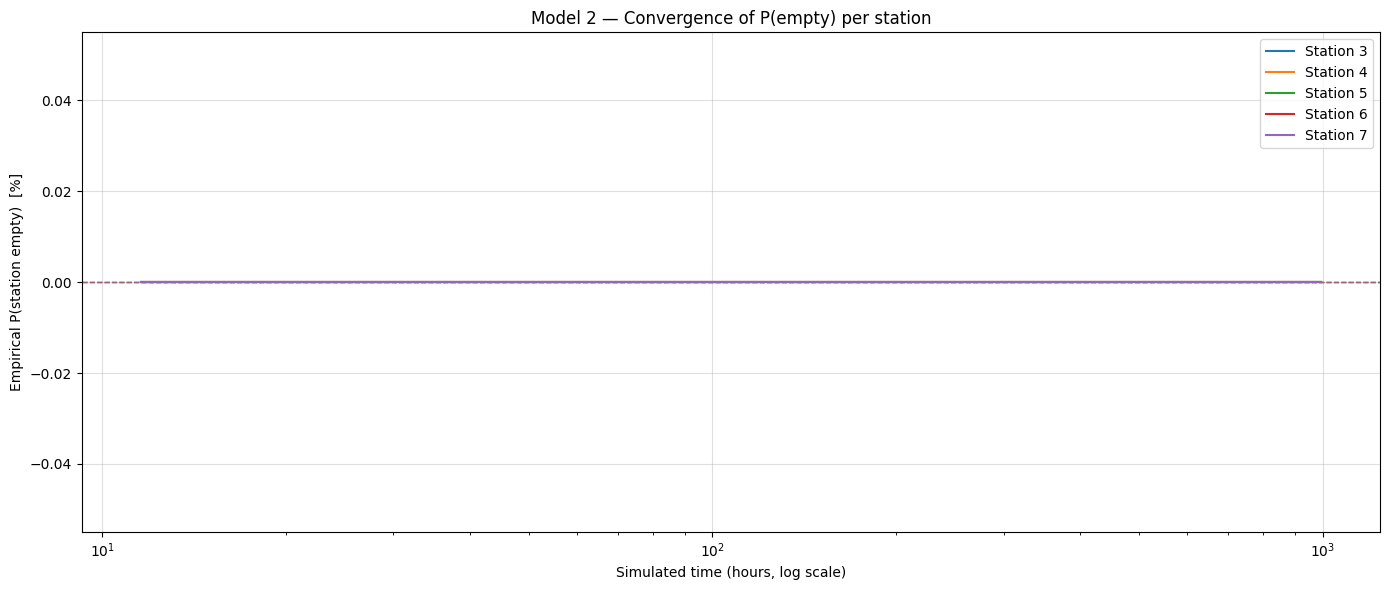

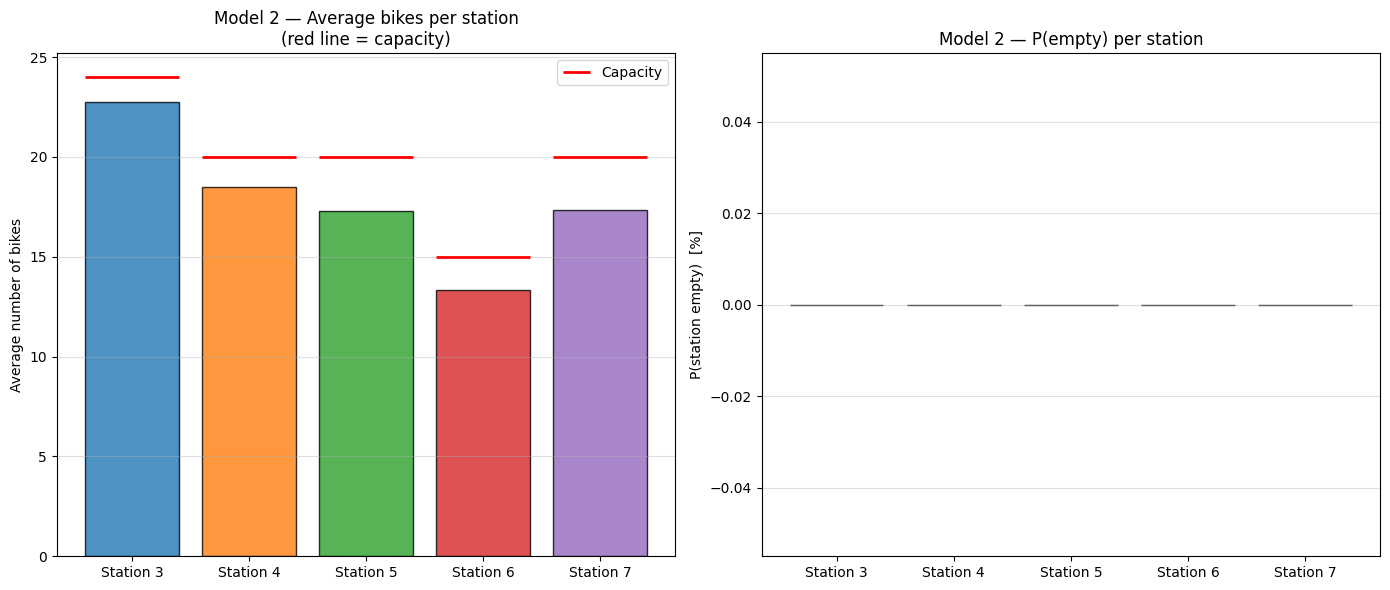

In [ ]:


random.seed(42)

stations = [3, 4, 5, 6, 7]

mu = [2.8, 3.7, 5.5, 3.5, 4.6]

P = [
    [0.0,  0.2,  0.3,  0.2,  0.3 ],
    [0.2,  0.0,  0.3,  0.2,  0.3 ],
    [0.2,  0.25, 0.0,  0.25, 0.3 ],
    [0.15, 0.2,  0.3,  0.0,  0.35],
    [0.2,  0.25, 0.35, 0.2,  0.0 ]
]

D_minutes = [
    [0, 3, 5, 7, 7],
    [2, 0, 2, 5, 5],
    [4, 2, 0, 3, 3],
    [8, 6, 4, 0, 2],
    [7, 7, 5, 2, 0]
]
D = [[t / 60.0 for t in row] for row in D_minutes]

K = [24, 20, 20, 15, 20]

initial_bikes = [20, 15, 17, 13, 18]

initial_bikes_in_transit = [
    [0, 1, 0, 0, 0],
    [1, 0, 1, 0, 0],
    [0, 1, 0, 1, 0],
    [0, 0, 1, 0, 1],
    [0, 0, 0, 1, 0]
]


def model_2(mu, P, D, K, t_max, initial_bikes, initial_bikes_in_transit, record_step=500):
    state = initial_bikes.copy()
    t = 0
    event_queue = []

    # --- Statistics ---
    bike_time_integral = np.zeros(5)
    empty_time = np.zeros(5)

    history_pi = []
    history_t  = []
    n_events   = 0

    # -------------------------------
    # 1. INITIAL DEPARTURES
    # -------------------------------
    for i in range(5):
        if state[i] > 0:
            departure_time = random.expovariate(mu[i])
            heapq.heappush(event_queue, (departure_time, 'DEPARTURE', i, None))

    # -------------------------------
    # 2. INITIAL ROUTE BIKES
    # -------------------------------
    for i in range(5):
        for j in range(5):
            if i != j:
                n_ij = initial_bikes_in_transit[i][j]
                for _ in range(n_ij):
                    remaining_time = random.uniform(0, D[i][j])
                    heapq.heappush(event_queue, (remaining_time, 'ARRIVAL', i, j))

    # -------------------------------
    # 3. MAIN LOOP
    # -------------------------------
    while event_queue:
        event_time, event_type, origin, destination = heapq.heappop(event_queue)

        if event_time > t_max:
            dt = t_max - t
            for i in range(5):
                bike_time_integral[i] += state[i] * dt
                if state[i] == 0:
                    empty_time[i] += dt
            break

        # Update statistics
        dt = event_time - t
        for i in range(5):
            bike_time_integral[i] += state[i] * dt
            if state[i] == 0:
                empty_time[i] += dt

        t = event_time

        # -------------------------------
        # DEPARTURE EVENT
        # -------------------------------
        if event_type == 'DEPARTURE':
            if state[origin] > 0:
                state[origin] -= 1

                dest = random.choices(range(5), weights=P[origin])[0]

                arrival_time = t + D[origin][dest]
                heapq.heappush(event_queue, (arrival_time, 'ARRIVAL', origin, dest))

                if state[origin] > 0:
                    next_departure = t + random.expovariate(mu[origin])
                    heapq.heappush(event_queue, (next_departure, 'DEPARTURE', origin, None))

        # -------------------------------
        # ARRIVAL EVENT
        # -------------------------------
        elif event_type == 'ARRIVAL':
            if state[destination] < K[destination]:
                was_empty = (state[destination] == 0)
                state[destination] += 1

                if was_empty:
                    next_departure = t + random.expovariate(mu[destination])
                    heapq.heappush(event_queue, (next_departure, 'DEPARTURE', destination, None))

            else:
                current = destination
                candidates = [
                    (D[current][k], k)
                    for k in range(5)
                    if k != current and state[k] < K[k]
                ]

                if candidates:
                    _, new_dest = min(candidates, key=lambda x: x[0])
                    new_arrival = t + D[current][new_dest]
                    heapq.heappush(event_queue, (new_arrival, 'ARRIVAL', current, new_dest))
                else:
                    pass  # bike lost if every station is full.

        n_events += 1
        if n_events % record_step == 0:
            history_pi.append((empty_time / t).copy())
            history_t.append(t)

    avg_bikes  = bike_time_integral / t_max
    prob_empty = empty_time / t_max

    return t, state, avg_bikes, prob_empty, history_pi, history_t


# -------------------------------
# RUN SIMULATION
# -------------------------------
print("=" * 60)
print("MODEL 2  —  Travel times + Capacities + Initial route bikes")
print("=" * 60)

t_max_2 = 1000
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

t_final_2, final_state_2, avg_bikes_2, prob_empty_2, history_pi_2, history_t_2 = model_2(
    mu, P, D, K, t_max_2, initial_bikes, initial_bikes_in_transit
)

print(f"\nSimulation time : {t_max_2:,} hours")
print(f"\n{'Station':<10} {'Avg bikes':>12} {'P(empty)':>12}")
print("-" * 36)
for i in range(5):
    print(f"  {stations[i]:<8} {avg_bikes_2[i]:>12.3f} {prob_empty_2[i]*100:>11.4f}%")

# ── Plot 1: convergence of P(empty) ──────────────────────────────────────────
history_pi_arr_2 = np.array(history_pi_2)

fig, ax = plt.subplots(figsize=(14, 6))
for i in range(5):
    ax.plot(history_t_2, history_pi_arr_2[:, i] * 100,
            label=f'Station {stations[i]}', color=colors[i], lw=1.5)
    ax.axhline(prob_empty_2[i] * 100, color=colors[i],
               linestyle='--', alpha=0.5, lw=1)
ax.set_xscale('log')
ax.set_xlabel('Simulated time (hours, log scale)')
ax.set_ylabel('Empirical P(station empty)  [%]')
ax.set_title('Model 2 — Convergence of P(empty) per station')
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

# ── Plot 2: average bikes + P(empty) bar charts ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax1 = axes[0]
x = np.arange(5)
bars = ax1.bar(x, avg_bikes_2, color=colors, alpha=0.8, edgecolor='black')
for i, cap in enumerate(K):
    ax1.hlines(cap, x[i] - 0.4, x[i] + 0.4, color='red', lw=2,
               label='Capacity' if i == 0 else "")
ax1.set_xticks(x)
ax1.set_xticklabels([f'Station {s}' for s in stations])
ax1.set_ylabel('Average number of bikes')
ax1.set_title('Model 2 — Average bikes per station\n(red line = capacity)')
ax1.legend()
ax1.grid(True, alpha=0.4, axis='y')

ax2 = axes[1]
ax2.bar(x, prob_empty_2 * 100, color=colors, alpha=0.8, edgecolor='black')
ax2.set_xticks(x)
ax2.set_xticklabels([f'Station {s}' for s in stations])
ax2.set_ylabel('P(station empty)  [%]')
ax2.set_title('Model 2 — P(empty) per station')
ax2.grid(True, alpha=0.4, axis='y')

plt.tight_layout()
plt.show()

### Results

The recorded 1,000-hour run reports no observed empty-station time at the displayed precision. I interpret this as a result of this particular run, rather than proof that the true empty-station probability is zero.

The fleet is more evenly distributed than in Model 1: Station 3 holds about 22.7 bikes on average, compared with about 71 in the baseline. Station 6 has the lowest mean occupancy, about 13.4 bikes, and the smallest capacity ($K_6=15$).

Mean occupancies below capacity do not rule out individual full-station arrivals. I next consider waiting queues and a rebalancing policy to investigate congestion more directly.

## Model 4: Waiting queues at full stations

I retain finite docking capacities but replace rerouting with a waiting queue. A bicycle arriving at a full station joins $w_j$ and waits for a dock. The fleet remains within the closed network.

The docking rules are

$$n_j<K_j \implies n_j\to n_j+1,$$
$$n_j=K_j \implies w_j\to w_j+1.$$

I retain a single station-level departure process:

$$\Phi_j(n_j)=\mu_j \quad\text{when }n_j>0.$$

Here, $K_j$ limits docked bicycles; the external waiting queue is separate. This differs from a standard $M/M/1/K$ loss queue, where arrivals are rejected when total capacity is reached.

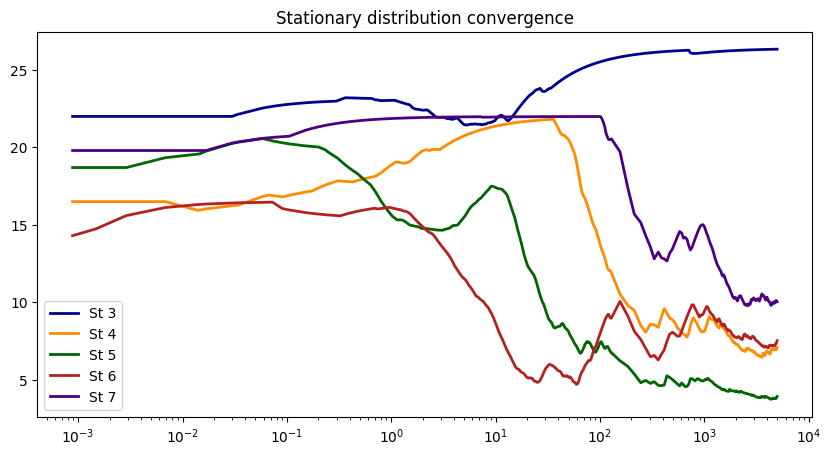

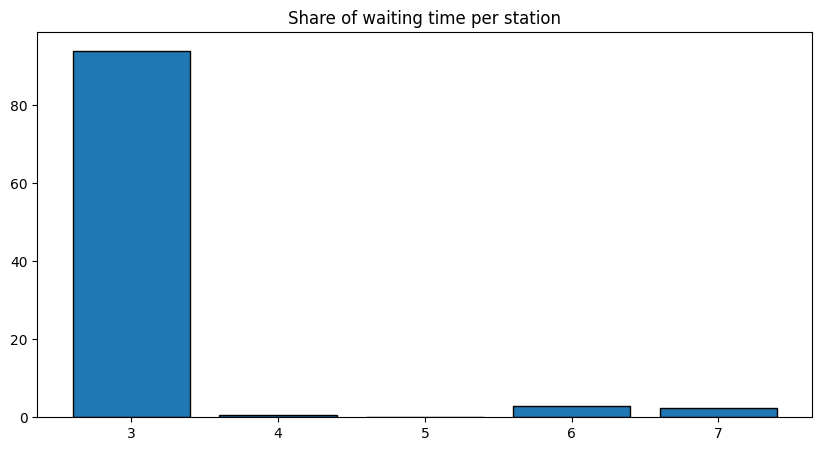

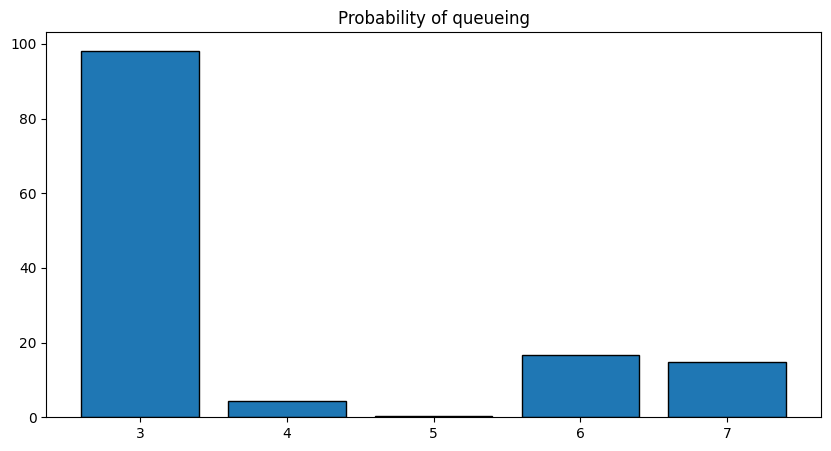

In [ ]:
# Model 4: queue-based system (bikes wait instead of being rerouted)

import random
import heapq
import numpy as np
import matplotlib.pyplot as plt

# Number of stations and labels used for plots
station_labels = [3, 4, 5, 6, 7]
J = 5

# Service rate at each station (rate at which bikes leave once docked)
mu = np.array([2.8, 3.7, 5.5, 3.5, 4.6])

# Routing probabilities: where a bike goes after leaving a station
P = np.array([
    [0.0, 0.2, 0.3, 0.2, 0.3],
    [0.2, 0.0, 0.3, 0.2, 0.3],
    [0.2, 0.25, 0.0, 0.25, 0.3],
    [0.15, 0.2, 0.3, 0.0, 0.35],
    [0.2, 0.25, 0.35, 0.2, 0.0]
])

# Travel times between stations (converted to hours)
D_min = [
    [0, 3, 5, 7, 7],
    [2, 0, 2, 5, 5],
    [4, 2, 0, 3, 3],
    [8, 6, 4, 0, 2],
    [7, 7, 5, 2, 0]
]
D = [[t / 60.0 for t in row] for row in D_min]

# Maximum capacity of each station
K = [24, 20, 20, 15, 20]

# Initial number of bikes at each station
initial_bikes = [20, 15, 17, 13, 18]

# Bikes already traveling between stations at time 0
initial_bikes_in_transit = [
    [0, 1, 0, 0, 0],
    [1, 0, 1, 0, 0],
    [0, 1, 0, 1, 0],
    [0, 0, 1, 0, 1],
    [0, 0, 0, 1, 0]
]

# Total number of bikes in the system (remains constant)
N_total = sum(initial_bikes) + sum(sum(row) for row in initial_bikes_in_transit)


def simulation_model3(mu, P, D, K, t_max, initial_bikes, initial_bikes_in_transit):
    """
    Discrete-event simulation of the bike system.
    If a station is full, arriving bikes wait in a queue instead of being rerouted.
    """

    # Current number of bikes docked at each station
    state = list(initial_bikes)

    # Queue length at each station (waiting bikes)
    waiting_queue = np.zeros(J)

    # Current simulation time
    t = 0.0

    # Event list (priority queue ordered by event time)
    event_queue = []

    # Time accumulators used to compute averages
    sum_docked_time = np.zeros(J)
    sum_waiting_time = np.zeros(J)
    sum_queue_exists_time = np.zeros(J)

    # Count arrivals to estimate arrival rates
    total_arrivals = np.zeros(J)

    # Store time evolution for plotting
    history_pi, history_Wq, history_Pq, history_t = [], [], [], []

    # Initialize departure events for stations that have bikes
    for i in range(J):
        if state[i] > 0:
            heapq.heappush(event_queue, (random.expovariate(mu[i]), 'DEPARTURE', i, None))

    # Initialize bikes already in transit
    for i in range(J):
        for j in range(J):
            if i != j and initial_bikes_in_transit[i][j] > 0:
                for _ in range(initial_bikes_in_transit[i][j]):
                    heapq.heappush(event_queue, (random.uniform(0.0, D[i][j]), 'ARRIVAL', i, j))

    n_events = 0

    # Main simulation loop
    while event_queue:
        event_time, event_type, origin, destination = heapq.heappop(event_queue)

        # Stop simulation at t_max and finalize statistics
        if event_time > t_max:
            dt = t_max - t
            for i in range(J):
                sum_docked_time[i] += state[i] * dt
                sum_waiting_time[i] += waiting_queue[i] * dt
                if waiting_queue[i] > 0:
                    sum_queue_exists_time[i] += dt
            break

        # Update time-based statistics over interval [t, event_time]
        dt = event_time - t
        for i in range(J):
            sum_docked_time[i] += state[i] * dt
            sum_waiting_time[i] += waiting_queue[i] * dt
            if waiting_queue[i] > 0:
                sum_queue_exists_time[i] += dt

        t = event_time

        if event_type == 'DEPARTURE':
            # A bike leaves the station
            state[origin] -= 1

            # If bikes are waiting, immediately serve the next one
            if waiting_queue[origin] > 0:
                waiting_queue[origin] -= 1
                state[origin] += 1
                heapq.heappush(event_queue, (t + random.expovariate(mu[origin]), 'DEPARTURE', origin, None))

            # If bikes remain, continue service
            elif state[origin] > 0:
                heapq.heappush(event_queue, (t + random.expovariate(mu[origin]), 'DEPARTURE', origin, None))

            # Choose next destination and schedule travel
            dest = random.choices(range(J), weights=P[origin])[0]
            heapq.heappush(event_queue, (t + D[origin][dest], 'ARRIVAL', origin, dest))

        elif event_type == 'ARRIVAL':
            total_arrivals[destination] += 1

            # If station has space, bike docks
            if state[destination] < K[destination]:
                was_empty = (state[destination] == 0)
                state[destination] += 1

                # If station was empty, start service
                if was_empty:
                    heapq.heappush(event_queue, (t + random.expovariate(mu[destination]), 'DEPARTURE', destination, None))
            else:
                # Otherwise, bike joins the queue
                waiting_queue[destination] += 1

        # Record metrics periodically to observe convergence
        n_events += 1
        if n_events < 5000 or n_events % 1000 == 0:
            cur_t = max(t, 1e-9)

            # Fraction of time bikes spend at each station
            history_pi.append(((sum_docked_time / cur_t) / N_total).copy())

            # Average waiting time (Little’s Law)
            cur_lam = total_arrivals / cur_t
            history_Wq.append(
                np.divide(sum_waiting_time / cur_t, cur_lam, out=np.zeros(J), where=cur_lam != 0).copy()
            )

            # Probability that a queue exists
            history_Pq.append((sum_queue_exists_time / cur_t).copy())
            history_t.append(t)

    return history_pi, history_Wq, history_Pq, history_t


# Run simulation
random.seed(42)
t_max_sim = 5000

h_pi, h_Wq, h_Pq, h_t = simulation_model3(
    mu, P, D, K, t_max_sim, initial_bikes, initial_bikes_in_transit
)

colors = ['darkblue', 'darkorange', 'darkgreen', 'firebrick', 'indigo']


# Plot convergence of station occupancy over time
plt.figure(figsize=(10, 5))
for i in range(J):
    plt.plot(h_t, np.array(h_pi)[:, i] * 100,
             label=f'St {station_labels[i]}',
             color=colors[i], lw=2)

plt.xscale('log')
plt.title("Stationary distribution convergence")
plt.legend()
plt.show()


# Plot how total waiting time is distributed across stations
Wq_f = np.array(h_Wq)[-1]
Wq_norm = (Wq_f / np.sum(Wq_f)) * 100

plt.figure(figsize=(10, 5))
plt.bar(range(J), Wq_norm, edgecolor='black')

plt.xticks(range(J), station_labels)
plt.title("Share of waiting time per station")
plt.show()


# Plot probability that a queue exists at each station
Pq_sim = np.array(h_Pq)[-1] * 100

plt.figure(figsize=(10, 5))
plt.bar(range(J), Pq_sim, edgecolor='black')

plt.xticks(range(J), station_labels)
plt.title("Probability of queueing")
plt.show()

In this scenario, I identify Station 3 as the main congestion point in the recorded run. Its station-level departure rate does not increase as bicycles accumulate. The 24 docks provide storage but do not increase departure throughput, so waiting bicycles can build up when arrivals outpace departures.

## Model 5: Greedy rebalancing

I add a simple rebalancing policy to the waiting-queue model. Every 24 hours, I compare station loads, defined as docked plus waiting bicycles ($n_j+w_j$). The policy selects the highest-load and lowest-load stations and transfers up to 15 bicycles between them, subject to the implementation's constraints.

This intervention targets the largest current imbalance while leaving the routing matrix $P$ unchanged. It provides an operational policy to compare with the unmanaged network.

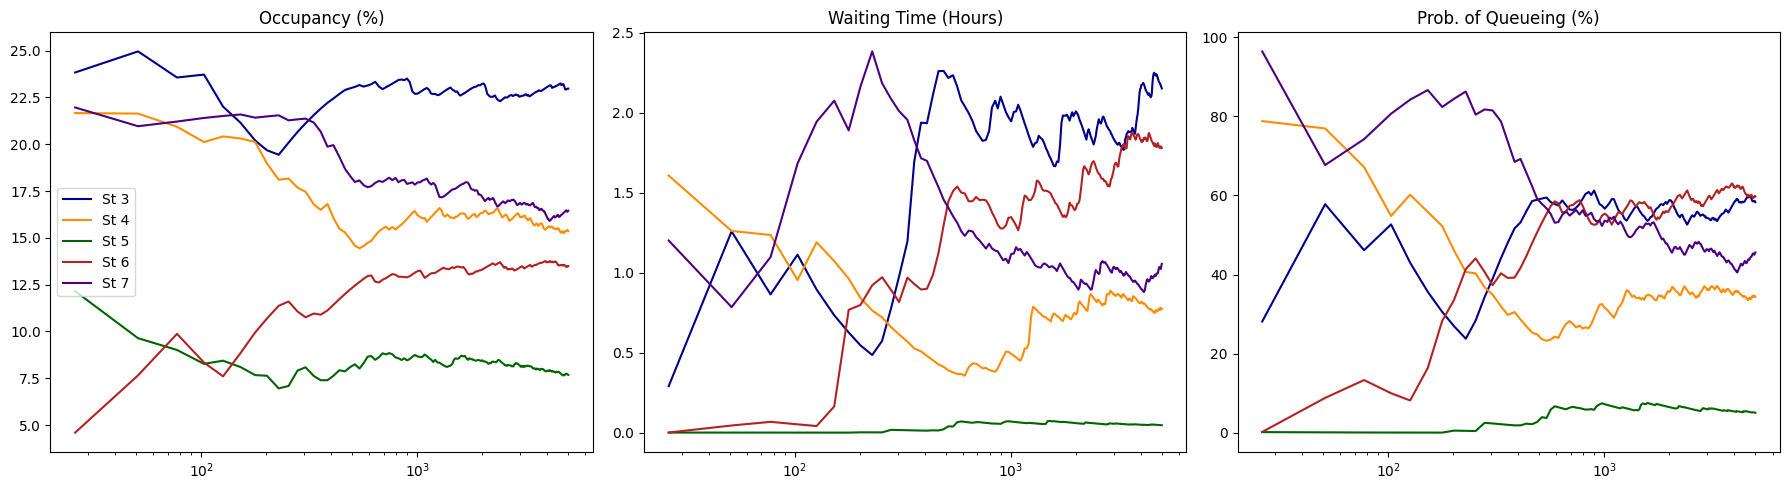

In [ ]:
import random
import heapq
import numpy as np
import matplotlib.pyplot as plt

# Configuration
station_labels = [3, 4, 5, 6, 7]
J = 5
mu = np.array([2.8, 3.7, 5.5, 3.5, 4.6])

P = np.array([
    [0.0, 0.2, 0.3, 0.2, 0.3],
    [0.2, 0.0, 0.3, 0.2, 0.3],
    [0.2, 0.25, 0.0, 0.25, 0.3],
    [0.15, 0.2, 0.3, 0.0, 0.35],
    [0.2, 0.25, 0.35, 0.2, 0.0]
])

D_min = [
    [0, 3, 5, 7, 7],
    [2, 0, 2, 5, 5],
    [4, 2, 0, 3, 3],
    [8, 6, 4, 0, 2],
    [7, 7, 5, 2, 0]
]
D = np.array(D_min) / 60.0
K = [24, 20, 20, 15, 20]

initial_bikes = [20, 15, 17, 13, 18]
initial_bikes_in_transit = [
    [0, 1, 0, 0, 0],
    [1, 0, 1, 0, 0],
    [0, 1, 0, 1, 0],
    [0, 0, 1, 0, 1],
    [0, 0, 0, 1, 0]
]

# Total bikes (including those in transit)
N_total = sum(initial_bikes) + sum(sum(row) for row in initial_bikes_in_transit)

def simulation_model5(mu, P, D, K, t_max, initial_bikes, initial_bikes_in_transit):
    state = list(initial_bikes)
    waiting_queue = np.zeros(J)
    t = 0.0
    calendar = []

    # Statistics
    sum_docked_time = np.zeros(J)
    sum_waiting_time = np.zeros(J)
    sum_queue_exists_time = np.zeros(J)
    total_arrivals = np.zeros(J)

    history_pi, history_Wq, history_Pq, history_t = [], [], [], []

    # Initialize departures
    for i in range(J):
        if state[i] > 0:
            heapq.heappush(calendar, (random.expovariate(mu[i]), 'D', i, None))

    # Initialize transit
    for i in range(J):
        for j in range(J):
            for _ in range(initial_bikes_in_transit[i][j]):
                heapq.heappush(calendar, (random.uniform(0.0, D[i][j]), 'A', i, j))

    # Redistribution Trigger (Every 24 hours)
    heapq.heappush(calendar, (24.0, 'R', None, None))

    events = 0
    while calendar:
        time, typ, i, j = heapq.heappop(calendar)
        if time > t_max:
            dt = t_max - t
            sum_docked_time += np.array(state) * dt
            sum_waiting_time += waiting_queue * dt
            sum_queue_exists_time += (waiting_queue > 0) * dt
            break

        dt = time - t
        sum_docked_time += np.array(state) * dt
        sum_waiting_time += waiting_queue * dt
        sum_queue_exists_time += (waiting_queue > 0) * dt
        t = time

        if typ == 'D':
            if state[i] > 0:
                state[i] -= 1
                if waiting_queue[i] > 0:
                    waiting_queue[i] -= 1
                    state[i] += 1
                    heapq.heappush(calendar, (t + random.expovariate(mu[i]), 'D', i, None))
                elif state[i] > 0:
                    heapq.heappush(calendar, (t + random.expovariate(mu[i]), 'D', i, None))

                dest = random.choices(range(J), weights=P[i])[0]
                heapq.heappush(calendar, (t + D[i][dest], 'A', i, dest))

        elif typ == 'A':
            total_arrivals[j] += 1
            if state[j] < K[j]:
                was_empty = (state[j] == 0)
                state[j] += 1
                if was_empty:
                    heapq.heappush(calendar, (t + random.expovariate(mu[j]), 'D', j, None))
            else:
                waiting_queue[j] += 1

        elif typ == 'R':
            # --- GREEDY REDISTRIBUTION: LARGEST TO SMALLEST ---
            load = np.array(state) + np.array(waiting_queue)
            src = np.argmax(load)
            trg = np.argmin(load)

            # Van capacity: moves up to 15 bikes
            moved = min(15, int(load[src]))

            # 1. Remove from source (prioritize removing from queue)
            from_queue = min(moved, int(waiting_queue[src]))
            waiting_queue[src] -= from_queue
            state[src] -= (moved - from_queue)

            # 2. Add to target (prioritize filling docks)
            space = K[trg] - state[trg]
            to_dock = min(moved, int(space))
            state[trg] += to_dock
            waiting_queue[trg] += (moved - to_dock)

            # 3. Synchronize departures for modified stations
            # (Clear existing departures for src/trg and re-init based on new state)
            calendar = [e for e in calendar if not (e[1] == 'D' and e[2] in [src, trg])]
            heapq.heapify(calendar)

            for station_idx in [src, trg]:
                if state[station_idx] > 0:
                    heapq.heappush(calendar, (t + random.expovariate(mu[station_idx]), 'D', station_idx, None))

            # Schedule next rebalancing
            heapq.heappush(calendar, (t + 24.0, 'R', None, None))

        events += 1
        if events % 1000 == 0:
            cur_t = max(t, 1e-9)
            history_pi.append(((sum_docked_time / cur_t) / N_total).copy())
            lam = total_arrivals / cur_t
            wq = np.divide(sum_waiting_time / cur_t, lam, out=np.zeros(J), where=lam != 0)
            history_Wq.append(wq.copy())
            history_Pq.append((sum_queue_exists_time / cur_t).copy())
            history_t.append(t)

    return np.array(history_t), np.array(history_pi), np.array(history_Wq), np.array(history_Pq)

# Run and Plot
random.seed(42)
t_hist, pi_hist, wq_hist, pq_hist = simulation_model5(mu, P, D, K, 5000, initial_bikes, initial_bikes_in_transit)
colors = ['darkblue', 'darkorange', 'darkgreen', 'firebrick', 'indigo']

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

for i in range(J):
    axs[0].plot(t_hist, pi_hist[:, i] * 100, label=f'St {station_labels[i]}', color=colors[i])
axs[0].set_xscale('log')
axs[0].set_title("Occupancy (%)")
axs[0].legend()

for i in range(J):
    axs[1].plot(t_hist, wq_hist[:, i], color=colors[i])
axs[1].set_xscale('log')
axs[1].set_title("Waiting Time (Hours)")

for i in range(J):
    axs[2].plot(t_hist, pq_hist[:, i] * 100, color=colors[i])
axs[2].set_xscale('log')
axs[2].set_title("Prob. of Queueing (%)")

plt.tight_layout()
plt.show()

The recorded simulation suggests that periodic redistribution can ease local load imbalances. Each intervention affects one station pair and moves a limited number of bicycles, so congestion can return between interventions.

I interpret this policy as a partial corrective measure. A precise estimate of its benefit would require repeated comparisons with the unmanaged model using the same performance metrics and simulation settings.

## Model 6: Parallel departures and an Erlang-C benchmark

I explore an alternative departure assumption: each docked bicycle has an independent exponential departure clock with rate $\mu_j$. This changes the interpretation of $\mu_j$ from a station-level rate to a per-bike rate.

The aggregate departure intensity is

$$\Phi_j(n_j)=\min(n_j,K_j)\mu_j.$$

I also calculate an Erlang-C benchmark with $s=K_j$ and $\rho=\lambda/(s\mu)$. Erlang-C describes an open $M/M/s$ queue with an infinite waiting buffer and requires $\rho<1$ for stationarity. I use it as an approximate comparison, rather than an exact solution of the closed bike-sharing network.

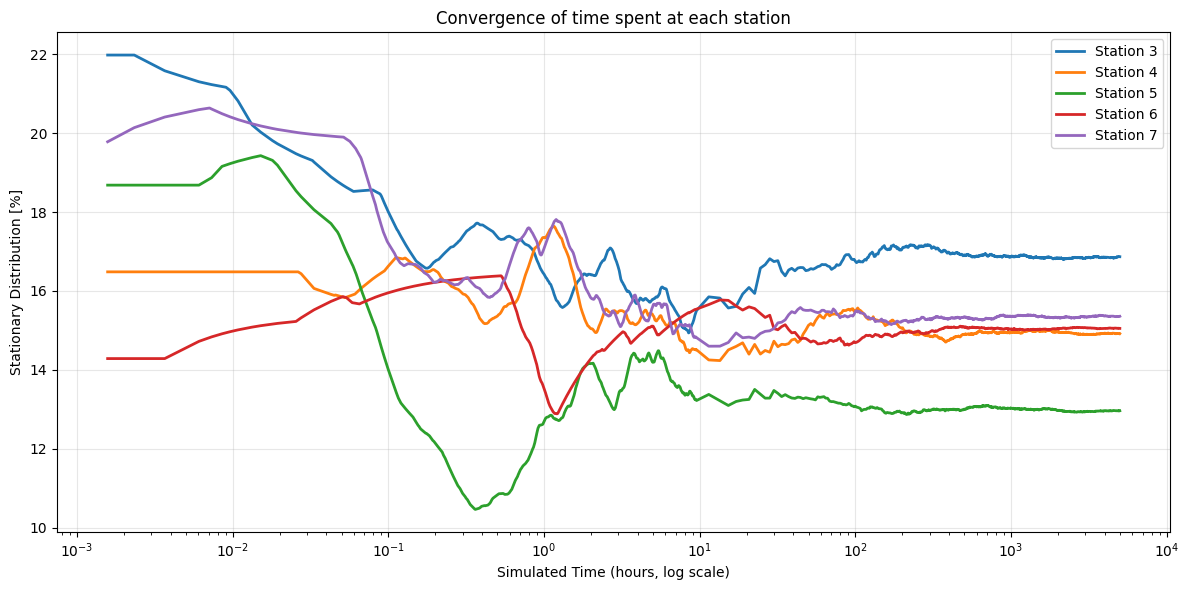

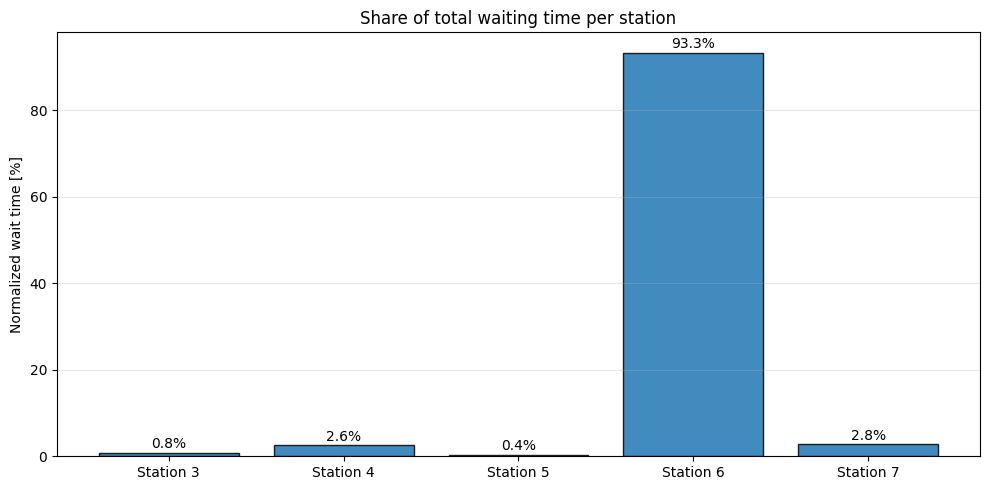

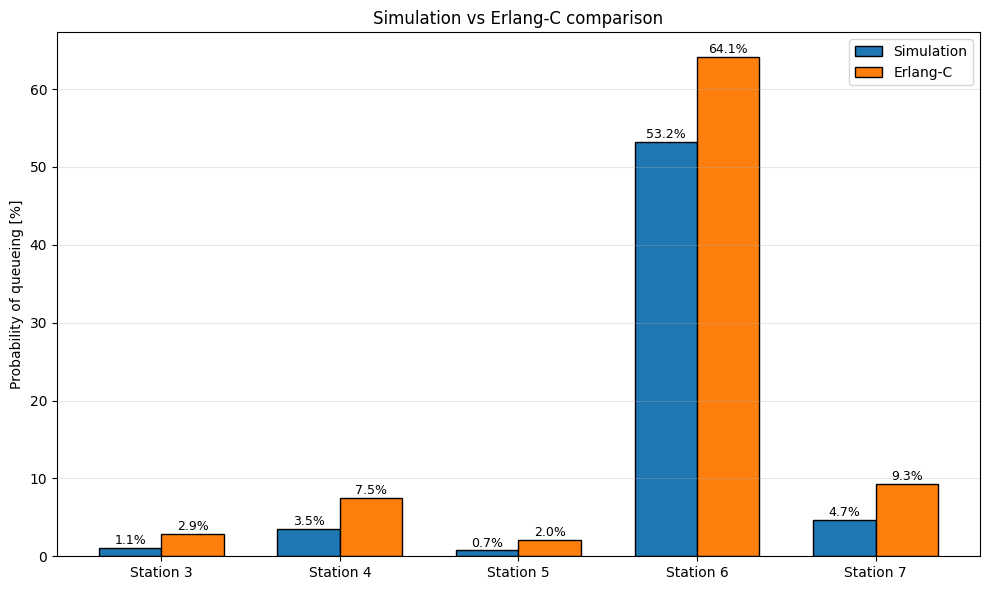

In [ ]:
#model 6 M/M/S, just to be in line with erlang C
import random
import heapq
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

# Number of stations and labels used in plots
station_labels = [3, 4, 5, 6, 7]
J = 5

# Service rate at each station (rate at which bikes leave when docked)
mu = np.array([2.8, 3.7, 5.5, 3.5, 4.6])

# Probability of choosing destination j after leaving station i
P = np.array([
    [0.0,  0.2,  0.3,  0.2,  0.3 ],
    [0.2,  0.0,  0.3,  0.2,  0.3 ],
    [0.2,  0.25, 0.0,  0.25, 0.3 ],
    [0.15, 0.2,  0.3,  0.0,  0.35],
    [0.2,  0.25, 0.35, 0.2,  0.0 ]
])

# Travel times between stations (converted to hours)
D_minutes = [
    [0, 3, 5, 7, 7],
    [2, 0, 2, 5, 5],
    [4, 2, 0, 3, 3],
    [8, 6, 4, 0, 2],
    [7, 7, 5, 2, 0]
]
D = [[t / 60.0 for t in row] for row in D_minutes]

# Maximum number of bikes each station can hold
K = [24, 20, 20, 15, 20]

# Initial number of bikes at each station
initial_bikes = [20, 15, 17, 13, 18]

# Bikes already traveling between stations at time 0
initial_bikes_in_transit = [
    [0, 1, 0, 0, 0],
    [1, 0, 1, 0, 0],
    [0, 1, 0, 1, 0],
    [0, 0, 1, 0, 1],
    [0, 0, 0, 1, 0]
]

# Total number of bikes (closed system: constant over time)
N_total = sum(initial_bikes) + sum(sum(row) for row in initial_bikes_in_transit)


def get_erlang_c_prob(s, lam, mu_val):
    """
    Computes the probability that an arriving bike has to wait
    in an M/M/s queue (used here as a theoretical benchmark).
    """
    a = lam / mu_val

    # If load exceeds capacity, system is saturated
    if a >= s:
        return 1.0

    try:
        num = (a**s / factorial(s)) * (s / (s - a))
        den = sum((a**k / factorial(k)) for k in range(s)) + num
        return num / den
    except OverflowError:
        return 1.0


def simulation_model3_multi_server(mu, P, D, K, t_max, initial_bikes, initial_bikes_in_transit):
    """
    Discrete-event simulation of a bike-sharing system.
    Each station behaves like an M/M/s/K queue with multiple servers.
    """

    # Current number of bikes at each station
    state = list(initial_bikes)

    # Number of bikes waiting when station is full
    waiting_queue = np.zeros(J)

    # Current simulation time
    t = 0.0

    # Priority queue of future events (min-heap by time)
    event_queue = []

    # Time integrals used to compute averages
    sum_docked_time = np.zeros(J)
    sum_waiting_time = np.zeros(J)
    sum_queue_exists_time = np.zeros(J)

    # Count arrivals to estimate arrival rates
    total_arrivals = np.zeros(J)

    # Store metrics over time (for convergence plots)
    history_pi, history_Wq, history_Pq, history_t = [], [], [], []

    # Each bike currently docked gets its own departure clock
    for i in range(J):
        for _ in range(state[i]):
            heapq.heappush(event_queue, (random.expovariate(mu[i]), 'DEPARTURE', i, None))

    # Initialize bikes already traveling
    for i in range(J):
        for j in range(J):
            if i != j and initial_bikes_in_transit[i][j] > 0:
                for _ in range(initial_bikes_in_transit[i][j]):
                    heapq.heappush(event_queue, (random.uniform(0.0, D[i][j]), 'ARRIVAL', i, j))

    n_events = 0

    # Main event loop
    while event_queue:
        event_time, event_type, origin, destination = heapq.heappop(event_queue)

        # Stop when reaching simulation horizon
        if event_time > t_max:
            dt = t_max - t
            for i in range(J):
                sum_docked_time[i] += state[i] * dt
                sum_waiting_time[i] += waiting_queue[i] * dt
                if waiting_queue[i] > 0:
                    sum_queue_exists_time[i] += dt
            break

        # Update time-dependent statistics
        dt = event_time - t
        for i in range(J):
            sum_docked_time[i] += state[i] * dt
            sum_waiting_time[i] += waiting_queue[i] * dt
            if waiting_queue[i] > 0:
                sum_queue_exists_time[i] += dt

        t = event_time

        if event_type == 'DEPARTURE':
            # A bike leaves the station
            state[origin] -= 1

            # If there is a queue, immediately serve the next bike
            if waiting_queue[origin] > 0:
                waiting_queue[origin] -= 1
                state[origin] += 1
                heapq.heappush(event_queue, (t + random.expovariate(mu[origin]), 'DEPARTURE', origin, None))

            # Choose next destination and schedule arrival
            dest = random.choices(range(J), weights=P[origin])[0]
            heapq.heappush(event_queue, (t + D[origin][dest], 'ARRIVAL', origin, dest))

        elif event_type == 'ARRIVAL':
            total_arrivals[destination] += 1

            # If there is space, bike docks immediately
            if state[destination] < K[destination]:
                state[destination] += 1
                heapq.heappush(event_queue, (t + random.expovariate(mu[destination]), 'DEPARTURE', destination, None))
            else:
                # Otherwise, it joins the queue
                waiting_queue[destination] += 1

        # Save intermediate results to observe convergence
        n_events += 1
        if n_events < 5000 or n_events % 1000 == 0:
            cur_t = max(t, 1e-9)

            # Fraction of time bikes spend at each station
            history_pi.append(((sum_docked_time / cur_t) / N_total).copy())

            # Waiting time via Little’s Law
            cur_lam = total_arrivals / cur_t
            cur_Lq = sum_waiting_time / cur_t
            history_Wq.append(np.divide(cur_Lq, cur_lam, out=np.zeros_like(cur_Lq), where=cur_lam != 0).copy())

            # Probability that a queue exists
            history_Pq.append((sum_queue_exists_time / cur_t).copy())
            history_t.append(t)

    lam_final = total_arrivals / t_max
    return history_pi, history_Wq, history_Pq, history_t, lam_final


# Run simulation
random.seed(42)
t_max_sim = 5000

h_pi, h_Wq, h_Pq, h_t, lam_f = simulation_model3_multi_server(
    mu, P, D, K, t_max_sim, initial_bikes, initial_bikes_in_transit
)

# Convert lists to arrays for plotting
h_pi_arr = np.array(h_pi)
h_Wq_arr = np.array(h_Wq)
h_Pq_arr = np.array(h_Pq)

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
x_idx = np.arange(J)
x_labels = [f'Station {s}' for s in station_labels]


# Plot how the stationary distribution converges over time
plt.figure(figsize=(12, 6))
for i in range(J):
    plt.plot(h_t, h_pi_arr[:, i] * 100,
             label=f'Station {station_labels[i]}',
             color=colors[i], lw=2)

plt.xscale('log')
plt.xlabel('Simulated Time (hours, log scale)')
plt.ylabel('Stationary Distribution [%]')
plt.title('Convergence of time spent at each station')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Compare how waiting time is distributed across stations
Wq_final = h_Wq_arr[-1]
Wq_total = np.sum(Wq_final)
Wq_normalized = (Wq_final / Wq_total) * 100.0 if Wq_total > 0 else np.zeros(J)

plt.figure(figsize=(10, 5))
bars = plt.bar(x_idx, Wq_normalized, edgecolor='black', alpha=0.85)

plt.xticks(x_idx, x_labels)
plt.ylabel('Normalized wait time [%]')
plt.title('Share of total waiting time per station')
plt.grid(True, axis='y', alpha=0.3)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1,
             f'{yval:.1f}%', ha='center')

plt.tight_layout()
plt.show()


# Compare simulated queue probability with Erlang-C approximation
Pq_sim_final = h_Pq_arr[-1] * 100.0
Pq_theory = [get_erlang_c_prob(K[i], lam_f[i], mu[i]) * 100 for i in range(J)]

plt.figure(figsize=(10, 6))
width = 0.35

b1 = plt.bar(x_idx - width/2, Pq_sim_final, width,
             label='Simulation', edgecolor='black')
b2 = plt.bar(x_idx + width/2, Pq_theory, width,
             label='Erlang-C', edgecolor='black')

for bars in [b1, b2]:
    for b in bars:
        plt.text(b.get_x() + b.get_width()/2,
                 b.get_height() + 0.5,
                 f'{b.get_height():.1f}%',
                 ha='center', fontsize=9)

plt.xticks(x_idx, x_labels)
plt.ylabel('Probability of queueing [%]')
plt.title('Simulation vs Erlang-C comparison')
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

I interpret congestion through the combined effects of routing flows, departure rates, and docking capacity. Station 6 has the smallest capacity ($K_6=15$), which can make it vulnerable to arrival fluctuations. Its actual congestion also depends on the inflows generated by $P$ and the evolving fleet distribution.

Because the departure assumption differs from the earlier models, I treat this section as a separate modeling scenario rather than a direct estimate of the effect of adding docks.